# 1. Simulate and validate a cohort

This tutorial simulates a synthetic cohort from the pd_v2 generative model, validates it, checks it against the
model's design envelope and writes a data card. No real data are used.

In [1]:
from symphony_dt.data import check_envelope, simulate_cohort
from symphony_dt.governance import data_card_markdown

cohort = simulate_cohort(120, seed=7)
ds = cohort.dataset
ds

TwinDataset(participants=120, observations=1342, endpoints=['updrs3', 'moca', 'scopa_aut'])

The dataset is in long format: one row per participant, visit and endpoint. Time is whole days since baseline.

In [2]:
ds.observations.head()

,participant_id,time_days,endpoint,value
0,00001,0,updrs3,25.655514
1,00001,0,moca,29.598124
2,00001,0,scopa_aut,4.126074
3,00001,382,updrs3,24.379028
4,00001,382,moca,23.679435


In [3]:
ds.summary(min_cell=10)

{'participants': 120,
 'observations': 1342,
 'visits': 593,
 'median_visits_per_participant': 5.0,
 'max_follow_up_years': 10.63,
 'cohorts': {'Prodromal': 67, 'PD': 53},
 'observations_by_endpoint': {'updrs3': 531, 'scopa_aut': 408, 'moca': 403}}

The true global parameters are known, which is what makes simulation useful for checking a fit.

In [4]:
{k: round(v, 3) for k, v in list(cohort.truth().items())[:8]}

{'mu_r[1]': -2.603,
 'mu_r[2]': -3.805,
 'mu_r[3]': -3.374,
 'Gamma[1,1]': 0.371,
 'Gamma[1,2]': 0.699,
 'Gamma[1,3]': 0.103,
 'Gamma[2,1]': 0.381,
 'Gamma[2,2]': -0.204}

## The validity envelope

The envelope compares the dataset with the domain pd_v2 was designed for. Each departure is a coded warning.

In [5]:
check_envelope(ds).to_dict()

{'model': 'pd_v2', 'inside': True, 'warnings': []}

## A data card

The data card reports aggregate counts only, with small cells suppressed, and the dataset fingerprint.

In [6]:
print(data_card_markdown(ds, title="Synthetic cohort", source="symphony_dt.simulate_cohort, seed 7"))

# Synthetic cohort

**Source.** symphony_dt.simulate_cohort, seed 7

**Fingerprint.** `43b0ec95c80958e984a92745f1bb4d5df837557739bdbe3710e6c171aa0c93aa` (sha256 of the canonical dataset; the data are not included).

## Counts

| quantity | value |
|---|---|
| participants | 120 |
| observations | 1342 |
| visits | 593 |
| median visits per participant | 5.0 |
| max follow up years | 10.63 |

## Cohorts

| cohort | participants |
|---|---|
| Prodromal | 67 |
| PD | 53 |

## Observations by endpoint

| endpoint | observations |
|---|---|
| updrs3 | 531 |
| scopa_aut | 408 |
| moca | 403 |

## Instruments

| name | version | range | worsening | boundary |
|---|---|---|---|---|
| updrs3 | MDS-UPDRS 2008 | 0 to 132 | increase | truncated |
| moca | 8.1 | 0 to 30 | decrease | censored |
| scopa_aut | 23-item prorated | 0 to 69 | increase | truncated |

## Validity envelope (pd_v2)

No out-of-envelope feature was found.



## Plot one trajectory

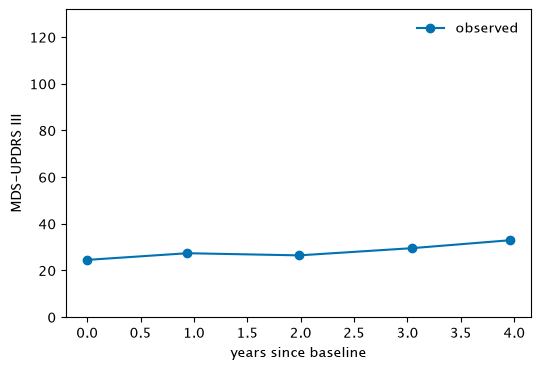

In [7]:
from symphony_dt.plots import plot_trajectory

plot_trajectory(ds, ds.participant_ids[3], endpoint="updrs3");